In [1]:
# Call source
from ga4_ecommerce_analytics_engine.sources.bigquery_source import BigQuerySource
start_date = '2020-11-01'
end_date = '2021-01-31'
source = BigQuerySource()
raw = source.fetch_all(start_date, end_date)

# Clean
from ga4_ecommerce_analytics_engine.cleaning.transactions import DataCleaner
cleaner = DataCleaner()
clean = cleaner.clean_transactions(raw.events, raw.items)

In [4]:
import networkx as nx
import polars as pl
import numpy as np
import hvplot.networkx as hvnx
import hvplot.polars as hvplot

# One-hot encode -> pivot long-to-wide
purchase_items = clean.items.filter(pl.col('event_name').eq('purchase'))
baskets = purchase_items.with_columns(present=pl.lit(1)).pivot(index='transaction_id', on='item_name', values='present', aggregate_function='first').fill_null(0)

# Build adjacency matrix -> get item-pair frequency.
baskets = baskets.drop('transaction_id')
item_names = np.array(baskets.columns, dtype=object)
baskets_np = baskets.to_numpy()
pairs = baskets_np.T @ baskets_np
support = pairs / baskets.shape[0]
freq = np.diag(support)
confidence = pairs / freq
lift = support / np.outer(freq, freq) 

i, j = np.triu_indices(len(baskets.columns)) # Get the upper-triangle indices of the matrix
antecedent, consequent = item_names[i].tolist(), item_names[j].tolist()
basket = [f"{a}{' + '}{c}" for a, c in zip(antecedent, consequent)]

basket_analysis = pl.DataFrame(
            {
                'antecedent': antecedent,
                'consequent': consequent,
                'basket': basket,
                'frequency': pairs[i, j],
                'support_of_basket': support[i, j],
                'confidence_of_first_item': confidence[i, j],
                'confidence_of_second_item': confidence[j, i],
                'lift': lift[i, j]
            }
        )

# Plot adjacency matrix
np.fill_diagonal(pairs,0)
G = nx.from_numpy_array(pairs)
mapping = {i: name for i, name in enumerate(baskets.columns)}
G = nx.relabel_nodes(G, mapping)
pairs = pl.from_numpy(pairs, schema=baskets.columns, orient='col')

In [5]:
weights = [val for node, val in list(nx.degree(G))]

sorted_weights = np.sort(weights)

# 3. Calculate empirical CDF values: P(X <= x)
# np.arange(1, N+1) / N gives proportional ranks
n = len(sorted_weights)
cdf = np.arange(1, n + 1) / n

# 4. Calculate CCDF: 1 - CDF -> P(X > x)
ccdf = 1.0 - cdf

# 5. Place into a structural DataFrame for plotting
ccdf_df = pl.DataFrame({
    "Edge_Weight": sorted_weights,
    "CCDF_Probability": ccdf
})

# Filter out absolute zero probabilities at the very end to prevent log axis crashes
ccdf_df = ccdf_df.filter(ccdf_df["CCDF_Probability"] > 0)

# Plot the CCDF using hvplot
ccdf_df.hvplot.scatter(
    x="Edge_Weight",
    y="CCDF_Probability",
    #logx=True,
    #logy=True,
    title="Network Backbone Analysis: Complementary CDF (CCDF)",
    xlabel="Edge Weight",
    ylabel="P(X > x)",
    width=720,
    height=450,
    color="#d35400",
    size=15,
    alpha=0.6,
    #xlim=(1e-3,1),
    #ylim=(1e-3,1.5)
)

:Scatter   [Edge_Weight]   (CCDF_Probability)

In [20]:
def prune(G, threshold):
    pruned_G = G.copy()
    weak_edges = [
            (u, v) for u, v, attrs in pruned_G.edges(data=True)
            if attrs.get("weight", 1) < threshold
        ]
    pruned_G.remove_edges_from(weak_edges)
    pruned_G.remove_nodes_from(list(nx.isolates(pruned_G)))
    return pruned_G

results = []
G_pruned = G.copy()
for threshold in range(0, max(weights)):
    G_pruned = prune(G_pruned, threshold)
    results.append({
        'threshold': threshold,
        'edges': G_pruned.number_of_edges(),
        'nodes': G_pruned.number_of_nodes(),
        'density': nx.density(G_pruned)
    })

graph = pl.DataFrame(results)
graph = graph.with_columns(
    ((pl.col('edges').first() - pl.col('edges')) / (pl.col('edges').first()) * 100).alias('edge_reduction')
)

with pl.Config(tbl_rows=20):
    display(graph.head(20))

threshold,edges,nodes,density,edge_reduction
i64,i64,i64,f64,f64
0,17170,392,0.224046,0.0
1,17170,392,0.224046,0.0
2,6386,370,0.093547,62.807222
3,2878,333,0.052064,83.238206
4,1511,286,0.037075,91.199767
5,896,233,0.033151,94.781596
6,607,192,0.033104,96.464764
7,426,157,0.034787,97.518928
8,299,135,0.033057,98.258591


In [24]:
G_pruned = prune(G, 4)
#G_pruned = G
print(nx.density(G_pruned))
print(G_pruned.number_of_nodes())
print(G_pruned.number_of_edges())

0.037075205496258125
286
1511


In [7]:
baseline_communities = nx.community.louvain_communities(G, seed=42)

num_baseline_groups = len(baseline_communities)
sizes = [len(c) for c in baseline_communities]
largest_group_size = max(sizes)
modularity = nx.community.modularity(G, baseline_communities)
print("📊 BASELINE COMMUNITY DIAGNOSTICS (UNPRUNED):")
print(f" 🔹 Total communities detected: {num_baseline_groups}")
print(f" 🔹 Size of the largest community: {largest_group_size} items")
print(f" 🔹 Average community size: {sum(sizes)/len(sizes):.1f} items")
print(f" 🔹 Modularity: {modularity:.4f}")

G_pruned = prune(G, 4)
pruned_communities = nx.community.louvain_communities(G_pruned, seed=42)
p_sizes = [len(c) for c in pruned_communities]
modularity = nx.community.modularity(G_pruned, pruned_communities)
print("\n✂️ POST-PRUNING COMMUNITY DIAGNOSTICS:")
print(f" 🔹 Total communities detected: {len(pruned_communities)}")
print(f" 🔹 Size of the largest community: {max(p_sizes)} items")
print(f" 🔹 Average community size: {sum(p_sizes)/len(p_sizes):.1f} items")
print(f" 🔹 Modularity: {modularity:.4f}")


📊 BASELINE COMMUNITY DIAGNOSTICS (UNPRUNED):
 🔹 Total communities detected: 9
 🔹 Size of the largest community: 109 items
 🔹 Average community size: 43.9 items
 🔹 Modularity: 0.1964

✂️ POST-PRUNING COMMUNITY DIAGNOSTICS:
 🔹 Total communities detected: 9
 🔹 Size of the largest community: 68 items
 🔹 Average community size: 31.8 items
 🔹 Modularity: 0.4245


In [8]:
profile_data = []

for idx, community in enumerate(pruned_communities):
    sub_G = G.subgraph(community)

    size = sub_G.number_of_nodes()
    density = nx.density(sub_G)

    total_weight = sum(attrs.get("weight", 1) for u, v, attrs in sub_G.edges(data=True))

    profile_data.append({
        'community_id': idx + 1,
        'item_count': size,
        'density': density,
        'internal_volume': total_weight,
        'sample_items': list(community)[:3]
    })

community_profile = pl.DataFrame(profile_data)
with pl.Config(tbl_rows=15, fmt_str_lengths=100):
    display(community_profile)

community_id,item_count,density,internal_volume,sample_items
i64,i64,f64,i64,list[str]
1,12,0.878788,228,"[""Google Clear Framed Blue Shades"", ""Google Blue YoYo"", ""Google Red YoYo""]"
2,45,0.477778,1214,"[""Android Iconic Beanie"", ""Google Cork Journal"", ""Google Mural Tote""]"
3,42,0.610918,1829,"[""Google Mural Sticky Note Pad"", ""Google Tee Grey"", ""Google Pen Grey""]"
4,24,0.543478,613,"[""Android Iconic Socks"", ""YouTube Icon Tee Grey"", ""YouTube Crew Socks""]"
5,45,0.521212,1490,"[""Google PNW Campus Zip Hoodie"", ""Google PNW Campus Lapel Pin"", ""Google LA Campus Sticker""]"
6,46,0.487923,1411,"[""Google Beekeepers Toddler Tee Pink"", ""Google Chrome Dinosaur Collectible"", ""Android Large Removable Sticker Sheet""]"
7,2,1.0,4,"[""Google Sunnyvale Campus Unisex Tee"", ""Google Sunnyvale Campus Ladies Tee""]"
8,68,0.420544,2466,"[""Google Badge Heavyweight Pullover Black"", ""Google Infant Hero Onesie Grey"", ""Google Soft Modal Scarf""]"
9,2,1.0,4,"[""Google PNW Campus Unisex Tee"", ""Google Kirkland Campus Ladies Tee""]"


In [29]:

def disparity_filter(G):
    """
    Computes alpha values (local p-values) for each edge based on the disparity filter.
    Handles weighted strength calculations accurately.
    """
    B = nx.Graph()
    
    # Calculate the strength (sum of edge weights) for every node in the graph
    # NetworkX returns this via graph.degree(weight='weight')
    strength_dict = dict(G.degree(weight='weight'))
    
    for u in G.nodes():
        k = G.degree(u)
        s = strength_dict[u]  # Node strength
        
        if k > 1 and s > 0:
            for v in G.neighbors(u):
                w = G[u][v]['weight']
                p = w / s
                
                # Statistical significance value alpha (closer to 0 means highly significant)
                alpha = (1.0 - p) ** (k - 1)
                
                # Maintain the lowest alpha if edge is processed from both sides
                if B.has_edge(u, v):
                    if alpha < B[u][v]['alpha']:
                        B[u][v]['alpha'] = alpha
                else:
                    B.add_edge(u, v, weight=w, alpha=alpha)
        elif k == 1:
            # Keep trivial single connections with an alpha of 0 to protect micro-niches
            neighbor = list(G.neighbors(u))[0]
            B.add_edge(u, neighbor, weight=G[u][neighbor]['weight'], alpha=0.0)
            
    return B

# --- Run the updated scoring mechanism ---

# 1. Score your current graph elements
scored_G = disparity_filter(G_pruned)

# 2. Extract backbone using a localized significance threshold (alpha < 0.05)
alpha_threshold = 0.05
G_backbone = nx.Graph()
for u, v, attrs in scored_G.edges(data=True):
    if attrs['alpha'] < alpha_threshold:
        G_backbone.add_edge(u, v, **attrs)
        
G_backbone.remove_nodes_from(list(nx.isolates(G_backbone)))


In [31]:
def compute_structural_dashboard(graph, communities, label="Graph"):
    # Calculate macro topology metrics
    modularity = nx.community.modularity(graph, communities)
    transitivity = nx.transitivity(graph)
    
    # Calculate degree statistics
    degrees = list(dict(graph.degree()).values())
    avg_degree = np.mean(degrees) if degrees else 0
    max_degree = np.max(degrees) if degrees else 0
    
    print(f"📊 TOPOLOGICAL METRICS FOR: {label}")
    print(f" 🔹 Active Catalog Size (Nodes):  {graph.number_of_nodes()}")
    print(f" 🔹 Core Corridors (Edges):       {graph.number_of_edges()}")
    print(f" 🔹 Community Modularity (Q):     {modularity:.4f}")
    print(f" 🔹 Triadic Transitivity Rate:    {transitivity:.4f}")
    print(f" 🔹 Average / Max Product Degree:  {avg_degree:.1f} / {max_degree}")
    print("-" * 50)

# Generate fresh comparative clusters on the local backbone
backbone_communities = nx.community.louvain_communities(G_backbone, seed=42)

# Compare your pruning paradigms side-by-side
compute_structural_dashboard(G_pruned, pruned_communities, label="Global Weight Prune (Weight >= 4)")
compute_structural_dashboard(G_backbone, backbone_communities, label="Local Disparity Backbone (Alpha < 0.05)")


📊 TOPOLOGICAL METRICS FOR: Global Weight Prune (Weight >= 4)
 🔹 Active Catalog Size (Nodes):  286
 🔹 Core Corridors (Edges):       1511
 🔹 Community Modularity (Q):     0.4245
 🔹 Triadic Transitivity Rate:    0.2960
 🔹 Average / Max Product Degree:  10.6 / 78
--------------------------------------------------
📊 TOPOLOGICAL METRICS FOR: Local Disparity Backbone (Alpha < 0.05)
 🔹 Active Catalog Size (Nodes):  99
 🔹 Core Corridors (Edges):       63
 🔹 Community Modularity (Q):     0.9200
 🔹 Triadic Transitivity Rate:    0.0682
 🔹 Average / Max Product Degree:  1.3 / 5
--------------------------------------------------


In [11]:
import polars as pl

# 1. Capture the exact edges that survived the local disparity filter
backbone_records = [
    {
        "item_A": u, 
        "item_B": v, 
        "co_occurrence_count": int(attrs.get("weight", 1)),
        "statistical_significance_alpha": float(attrs.get("alpha", 0))
    }
    for u, v, attrs in G_backbone.edges(data=True)
]

# 2. Convert to Polars and sort by the raw transactional volume
df_backbone_highways = (
    pl.DataFrame(backbone_records)
    .sort("co_occurrence_count", descending=True)
)

# 3. Print out your top 20 high-conviction product tracks
with pl.Config(tbl_rows=20, fmt_str_lengths=100):
    display(df_backbone_highways.head(20))


item_A,item_B,co_occurrence_count,statistical_significance_alpha
str,str,i64,f64
"""Google Light Pen Green""","""Google Light Pen Red""",42,0.001971
"""Google Light Pen Blue""","""Google Light Pen Red""",41,0.002323
"""Google Light Pen Blue""","""Google Light Pen Green""",37,0.006864
"""Android SM S/F18 Sticker Sheet""","""Android Large Removable Sticker Sheet""",32,0.004738
"""Google Crew Combed Cotton Sock""","""Google Crew Socks""",31,0.016081
"""Google Metallic Notebook Set""","""Google Clear Pen 4-Pack""",30,0.01175
"""Google Heathered Pom Beanie""","""Google Speckled Beanie Navy""",25,0.012874
"""Google Clear Framed Yellow Shades""","""Google Clear Framed Blue Shades""",25,0.033785
"""Google Heathered Pom Beanie""","""Google Speckled Beanie Grey""",22,0.027384


In [32]:
import polars as pl

# 1. Calculate degree (count of connections) and strength (volume of connections) on the backbone
hub_records = []
for node in G_backbone.nodes():
    hub_records.append({
        "item_name": node,
        "backbone_degree": int(G_backbone.degree(node)),
        "backbone_strength": int(G_backbone.degree(node, weight="weight"))
    })

# 2. Put into Polars and sort by degree first, then transactional strength
df_backbone_hubs = (
    pl.DataFrame(hub_records)
    .sort(["backbone_degree", "backbone_strength"], descending=[True, True])
)

# 3. View your top local hubs
with pl.Config(tbl_rows=15, fmt_str_lengths=100):
    print(df_backbone_hubs)


shape: (99, 3)
┌───────────────────────────────────────┬─────────────────┬───────────────────┐
│ item_name                             ┆ backbone_degree ┆ backbone_strength │
│ ---                                   ┆ ---             ┆ ---               │
│ str                                   ┆ i64             ┆ i64               │
╞═══════════════════════════════════════╪═════════════════╪═══════════════════╡
│ Google Heathered Pom Beanie           ┆ 5               ┆ 59                │
│ Android SM S/F18 Sticker Sheet        ┆ 4               ┆ 59                │
│ Google Red Speckled Tee               ┆ 4               ┆ 31                │
│ Google Chicago Campus Mug             ┆ 4               ┆ 19                │
│ Google Laptop and Cell Phone Stickers ┆ 3               ┆ 44                │
│ Google Clear Pen 4-Pack               ┆ 3               ┆ 38                │
│ Google Light Pen Red                  ┆ 2               ┆ 83                │
│ Google Light Pen Green 

In [33]:
asymmetry_records = []
for u in G_backbone.nodes():
    # Find the single strongest edge connected to this specific item
    neighbors = list(G_backbone.neighbors(u))
    if neighbors:
        max_edge_weight = max(G_backbone[u][v]['weight'] for v in neighbors)
        total_node_strength = sum(G_backbone[u][v]['weight'] for v in neighbors)
        
        # Dependency ratio: closer to 1.0 means this item is a complete captive hostage to its strongest neighbor
        dependency_ratio = max_edge_weight / total_node_strength if total_node_strength > 0 else 0
        
        asymmetry_records.append({
            "item_name": u,
            "strongest_neighbor_weight": max_edge_weight,
            "total_strength": total_node_strength,
            "dependency_ratio": dependency_ratio
        })

df_dependencies = pl.DataFrame(asymmetry_records).sort("dependency_ratio", descending=True)

with pl.Config(tbl_rows=15, fmt_str_lengths=100):
    print(df_dependencies)


shape: (99, 4)
┌──────────────────────────────────┬───────────────────────────┬────────────────┬──────────────────┐
│ item_name                        ┆ strongest_neighbor_weight ┆ total_strength ┆ dependency_ratio │
│ ---                              ┆ ---                       ┆ ---            ┆ ---              │
│ str                              ┆ i64                       ┆ i64            ┆ f64              │
╞══════════════════════════════════╪═══════════════════════════╪════════════════╪══════════════════╡
│ Google Incognito Techpack V2     ┆ 5                         ┆ 5              ┆ 1.0              │
│ Google Land & Sea French Terry   ┆ 5                         ┆ 5              ┆ 1.0              │
│ Sweatshirt                       ┆                           ┆                ┆                  │
│ Google Navy Speckled Tee         ┆ 18                        ┆ 18             ┆ 1.0              │
│ Google Mountain View Campus      ┆ 4                         ┆ 4          

In [34]:
parent_records = []
for u in G_backbone.nodes():
    neighbors = list(G_backbone.neighbors(u))
    # If it's a captive hostage, it has exactly 1 neighbor
    if len(neighbors) == 1:
        v = neighbors[0]
        parent_records.append({
            "captive_item": u,
            "hostage_parent_hub": v,
            "shared_transaction_volume": G_backbone[u][v]['weight']
        })

df_captive_pairs = pl.DataFrame(parent_records).sort("shared_transaction_volume", descending=True)

with pl.Config(tbl_rows=20, fmt_str_lengths=100):
    display(df_captive_pairs.head(20))


captive_item,hostage_parent_hub,shared_transaction_volume
str,str,i64
"""Android Large Removable Sticker Sheet""","""Android SM S/F18 Sticker Sheet""",32
"""Google Crew Combed Cotton Sock""","""Google Crew Socks""",31
"""Google Speckled Beanie Navy""","""Google Heathered Pom Beanie""",25
"""Google Clear Framed Blue Shades""","""Google Clear Framed Yellow Shades""",25
"""Google Speckled Beanie Grey""","""Google Heathered Pom Beanie""",22
"""Google Seattle Campus Mug""","""Google PNW Campus Mug""",22
"""Google Camp Mug Ivory""","""Google Camp Mug Gray""",21
"""Google Camp Mug Gray""","""Google Camp Mug Ivory""",21
"""Google Pen White""","""Google Laptop and Cell Phone Stickers""",21


In [15]:
# Create a mapping of our isolated pairs
dyad_mapping = {}
for row in df_captive_pairs.iter_rows(named=True):
    dyad_mapping[row["captive_item"]] = row["hostage_parent_hub"]

# Find edges in your unpruned graph G that connect separate dyads together
cross_dyad_records = []
for u, v, attrs in G.edges(data=True):
    if u in dyad_mapping and v in dyad_mapping:
        # Check if they belong to completely different isolated pairs
        if dyad_mapping[u] != v and dyad_mapping[v] != u:
            cross_dyad_records.append({
                "item_from_dyad_A": u,
                "item_from_dyad_B": v,
                "historical_cross_volume": attrs.get("weight", 1)
            })

df_inter_dyad_highways = pl.DataFrame(cross_dyad_records).sort("historical_cross_volume", descending=True)

with pl.Config(tbl_rows=15, fmt_str_lengths=100):
    print(df_inter_dyad_highways)


shape: (908, 3)
┌────────────────────────────────────┬───────────────────────────────────┬─────────────────────────┐
│ item_from_dyad_A                   ┆ item_from_dyad_B                  ┆ historical_cross_volume │
│ ---                                ┆ ---                               ┆ ---                     │
│ str                                ┆ str                               ┆ i64                     │
╞════════════════════════════════════╪═══════════════════════════════════╪═════════════════════════╡
│ Google Crewneck Sweatshirt Green   ┆ Google Crewneck Sweatshirt Navy   ┆ 16                      │
│ Google Zip Hoodie F/C              ┆ Super G Unisex Joggers            ┆ 15                      │
│ Google Clear Framed Blue Shades    ┆ Google Clear Framed Gray Shades   ┆ 15                      │
│ Google Crew Combed Cotton Sock     ┆ Google Crew Striped Athletic Sock ┆ 13                      │
│ Google Crewneck Sweatshirt Green   ┆ Google F/C Longsleeve Charcoal    ┆ 

In [ ]:
def analyze_original_graph_hubs(graph):
    # 1. Compute raw network metrics from NetworkX
    degree_dict = dict(graph.degree())
    
    # Node strength is the absolute sum of all attached edge transaction counts
    strength_dict = dict(graph.degree(weight="weight"))
    
    # Betweenness centrality tracks how often a product sits on the shortest 
    # purchasing path between all other items (requires inverted weight for distance)
    dist_G = graph.copy()
    for u, v, attrs in dist_G.edges(data=True):
        w = attrs.get("weight", 1)
        dist_G[u][v]["distance"] = 1.0 / w if w > 0 else 1.0
        
    betweenness_dict = nx.betweenness_centrality(dist_G, weight="distance", seed=42)
    
    # 2. Compile metrics into Polars
    hub_records = [
        {
            "product_name": node,
            "raw_degree": int(degree_dict[node]),
            "total_transaction_strength": int(strength_dict[node]),
            "betweenness_traffic_control": float(betweenness_dict[node])
        }
        for node in graph.nodes()
    ]
    
    return pl.DataFrame(hub_records).sort("total_transaction_strength", descending=True)

# Run the analyzer on the original graph object G
df_original_hubs = analyze_original_graph_hubs(G)

# Print out the top 15 structural hubs
with pl.Config(tbl_rows=15, fmt_str_lengths=100):
    display(df_original_hubs.head(10))


product_name,raw_degree,total_transaction_strength,betweenness_traffic_control
str,i64,i64,f64
"""Google Laptop and Cell Phone Stickers""",255,834,0.208732
"""Google Clear Pen 4-Pack""",242,808,0.171345
"""Google Camp Mug Ivory""",209,706,0.137069
"""Google Heathered Pom Beanie""",237,683,0.11107
"""Android SM S/F18 Sticker Sheet""",220,635,0.083046
"""Google Metallic Notebook Set""",210,634,0.062442
"""Google Pen White""",211,618,0.063991
"""Google Light Pen Blue""",224,591,0.019287
"""Google Magnet""",224,585,0.051998


In [35]:
# Hybrid Pruning: Keep edges that are EITHER locally significant OR globally heavy
G_hybrid = nx.Graph()
for u, v, attrs in scored_G.edges(data=True):
    # Condition: Local alpha is significant OR the raw volume is undeniable
    if attrs['alpha'] < 0.05 or attrs['weight'] >= 8:
        G_hybrid.add_edge(u, v, **attrs)

G_hybrid.remove_nodes_from(list(nx.isolates(G_hybrid)))


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
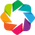

:Graph   [start,end]   (alpha,weight)

In [18]:
import networkx as nx
import holoviews as hv
import hvplot.networkx as hvnx
import polars as pl
import numpy as np

# 1. Initialize the HoloViews engine
hv.extension('bokeh')

# 2. Build the Hybrid Graph structure
G_hybrid = nx.Graph()
for u, v, attrs in scored_G.edges(data=True):
    # Condition: Local alpha is highly significant OR the raw volume is undeniable
    if attrs['alpha'] < 0.05 or attrs['weight'] >= 8:
        G_hybrid.add_edge(u, v, **attrs)

# Cleanly strip out dead isolated nodes to keep the canvas focused
G_hybrid.remove_nodes_from(list(nx.isolates(G_hybrid)))

# 3. Detect the new hybrid communities (bridges will naturally condense some groups)
hybrid_communities = nx.community.louvain_communities(G_hybrid, seed=42)
node_to_community = {node: idx + 1 for idx, c in enumerate(hybrid_communities) for node in c}

# 4. Inject structural properties into the graph nodes for interactive tooltips
for node in G_hybrid.nodes():
    c_id = node_to_community.get(node, 1)
    G_hybrid.nodes[node]['product_name'] = str(node)
    G_hybrid.nodes[node]['community_id'] = str(c_id) # Cast to string for discrete coloring
    G_hybrid.nodes[node]['hybrid_degree'] = G_hybrid.degree(node)

# 5. Compute the new force-directed layout
# Because bridges are back, the components will naturally arrange relative to their true gravity
pos_hybrid = nx.spring_layout(G_hybrid, k=0.35, iterations=150, seed=42)

# 6. Render the network map via hvnx
hybrid_network_view = hvnx.draw(
    G_hybrid,
    pos=pos_hybrid,
    node_color='community_id',
    cmap='Category20',                   # Expanded color palette to handle re-merged niches
    node_size=hv.dim('hybrid_degree') * 2.5 + 6,
    
    # Edge Styling: Differentiating local links from thick macro-highways
    edge_color='#cbd5e1',
    edge_alpha=0.5,
    edge_width=hv.dim('weight') * 0.12,
    
    # Bounding Box and Tools
    width=950,
    height=800,
    with_labels=False,
    title="Hybrid Topology Backbone: Restoring Cross-Department Strategic Bridges"
).opts(
    xaxis=None, yaxis=None,
    inspection_policy='nodes',
    tools=['hover', 'wheel_zoom', 'pan', 'reset']
)

# Display the balanced network visualization
hybrid_network_view


In [19]:
# Calculate and print metrics for the new hybrid structure
print("==================================================")
compute_structural_dashboard(G_hybrid, hybrid_communities, label="Hybrid Backbone (Alpha < 0.05 OR Weight >= 8)")


📊 TOPOLOGICAL METRICS FOR: Hybrid Backbone (Alpha < 0.05 OR Weight >= 8)
 🔹 Active Catalog Size (Nodes):  191
 🔹 Core Corridors (Edges):       343
 🔹 Community Modularity (Q):     0.6654
 🔹 Triadic Transitivity Rate:    0.2844
 🔹 Average / Max Product Degree:  3.6 / 22
--------------------------------------------------


In [51]:
from ga4_ecommerce_analytics_engine.analytics.gamma_scan import scan_resolution
import hvplot.polars
results = pl.DataFrame(scan_resolution(G))
results.hvplot.scatter(x='gamma', y='modularity')

:Scatter   [gamma]   (modularity)

In [53]:
results = pl.DataFrame(scan_resolution(prune(G, 4)))
results.hvplot.scatter(x='gamma',y='modularity')

:Scatter   [gamma]   (modularity)

In [55]:
results = pl.DataFrame(scan_resolution(G_hybrid))
results.hvplot.scatter(x='gamma',y='modularity')

:Scatter   [gamma]   (modularity)